# 3. Kriging, OOIP, uncertainty and the development decision

Every fitted model from notebook 2 is used for global ordinary kriging of porosity. Benchmarks:

| method | what it is |
|---|---|
| `loocv` | the type cross-validation picks for that dataset |
| `truth_variogram` | kriging with the model fitted to the exhaustive truth variogram (best achievable model) |
| `idw` | inverse-distance-squared map: a map from the wells that uses no variogram |
| `simulation_ev` | wells placed on the expected drained OOIP (E-type, normal-score model, Gauss-Hermite quadrature) |
| `naive` | declustered well mean everywhere |
| `random` | random well sites (average of 200 programs) |

**Decision** (PGE 338 Lecture 16c): place 3 development wells, each draining the OOIP within 150 m, at least 300 m apart,
on each map (greedy + swap improvement). **Primary metric: regret in $MM** = value of the truth-optimal program minus the
true value of the chosen program (RF 0.30, $35/bbl netback). OOIP per cell = 7758 A h phi (1 - Sw) / Bo with
Sw = 0.55 - 1.5 phi (clipped), h = 50 ft, Bo = 1.2.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from vstudy import config as C, plots, analysis as A, wells as W, fitting, kriging
from vstudy.pipeline import run_study, build_truth, build_dataset, dataset_rng
from vstudy.variography import Truth, lag_settings
pd.set_option('display.precision', 3); pd.set_option('display.width', 160)
R = run_study('main')
dec, est, unc = R['decisions'], R['estimates'], R['uncertainty']
MAPS = C.VTYPES + ['loocv', 'truth_variogram', 'idw']

## Example maps

Skewed scenario, truth 0, 50 preferential wells.

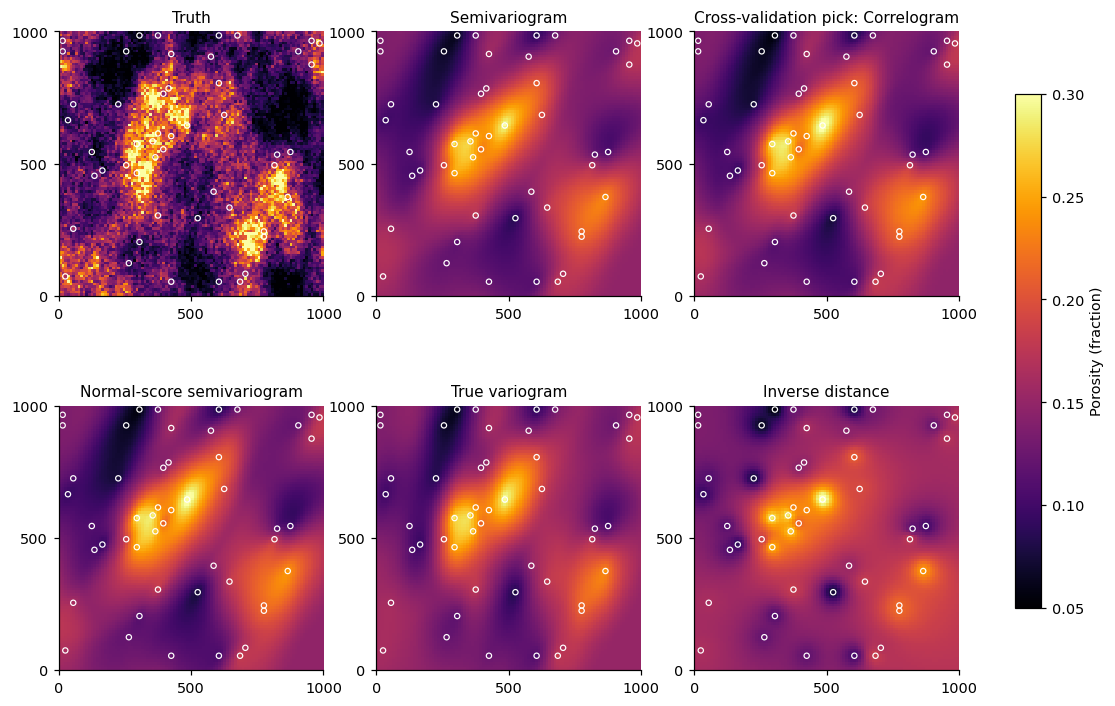

In [2]:
s, r, n, design = 'skewed', 0, 50, 'preferential'
phi = build_truth('main', s, r)[0]; ds = build_dataset('main', s, r, n, design, phi); w = ds['wells']
pick = R['fits'].query('scenario == @s and realization == @r and n_wells == @n and design == @design and picked').vtype.iloc[0]
ref = R['truths'].query('scenario == @s and realization == @r').iloc[0]
tm = dict(it=int(ref.ref_it), nug=ref.ref_nug, azi=ref.ref_azi, hmaj=ref.ref_hmaj, hmin=ref.ref_hmin)
ok = lambda m: kriging.ordinary_kriging(w['x'], w['y'], w['v'], m, w['var_d'])[0]
panels = [('Truth', phi), ('Semivariogram', ok(ds['models']['semivariogram'])), (f'Cross-validation pick: {C.LABEL[pick]}', ok(ds['models'][pick])),
          ('Normal-score semivariogram', ok(ds['models']['normal_score'])), ('True variogram', ok(tm)), ('Inverse distance', kriging.idw(w['x'], w['y'], w['v']))]
plots.maps(panels, wells=w, vmin=0.05, vmax=0.30); plt.show()

## Porosity map accuracy

Porosity RMSE, % worse than kriging with the true variogram.

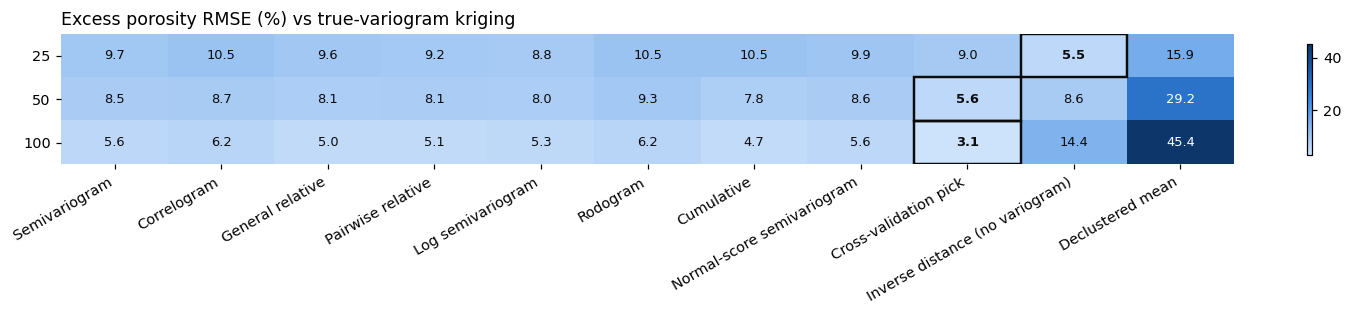

In [3]:
ex = A.by(est[est.method.isin(MAPS + ['naive'])], 'excess_rmse_pct', 'n_wells', 'method', [m for m in MAPS if m != 'truth_variogram'] + ['naive'])
plots.heat(ex, 'Excess porosity RMSE (%) vs true-variogram kriging', fmt='{:.1f}'); plt.show()

## OOIP

Mean absolute OOIP error (%), and the signed error by design: preferential wells bias OOIP high for every method.

In [4]:
display(A.by(est, 'abs_ooip_err_pct', 'n_wells', 'method', MAPS + ['naive']).round(2).rename_axis('|OOIP error| %'))
print('Signed OOIP error (%), positive = overestimate:')
A.by(est[est.method.isin(['semivariogram', 'loocv', 'idw', 'naive'])], 'ooip_err_pct', ['design', 'n_wells'], 'method').round(2)

method,semivariogram,correlogram,general_relative,pairwise_relative,log,rodogram,cumulative,normal_score,loocv,truth_variogram,idw,naive
|OOIP error| %,,,,,,,,,,,,
25,12.21,12.01,12.13,11.86,11.84,12.19,12.25,12.07,11.74,10.85,12.33,10.09
50,9.36,9.49,9.25,9.18,9.16,9.34,9.32,9.40,9.00,8.54,10.18,8.40
100,7.14,7.31,6.91,6.92,6.91,7.04,7.22,7.04,6.89,6.51,9.28,7.06


Signed OOIP error (%), positive = overestimate:


method                  idw  loocv  naive  semivariogram
design       n_wells                                    
preferential 25       17.57  16.27  13.04          16.91
             50       15.74  13.65  11.33          14.27
             100      14.82  10.86   9.38          11.25
random       25       -1.89  -1.39  -2.92          -1.27
             50       -2.62  -1.78  -3.67          -1.68
             100      -2.73  -1.47  -3.99          -1.52

## Is the uncertainty right?

Two checks. (1) Kriging variance: the share of cells whose true porosity lies inside the 90% kriging interval
(ideal 90). (2) Simulation: 50 conditional simulations per dataset with the normal-score model; how often the true
OOIP falls inside the simulated P10-P90 range (ideal 80).

In [5]:
cov = A.by(est[est.method.isin(['semivariogram', 'normal_score', 'loocv', 'truth_variogram'])], 'cover90', 'n_wells', 'method').round(1)
display(cov.rename_axis('% cells inside 90% kriging interval'))
(100 * unc.groupby(['design', 'n_wells']).inside_p10_p90.mean().unstack()).round(0).rename_axis('% truths inside simulated P10-P90')

method,loocv,normal_score,semivariogram,truth_variogram
% cells inside 90% kriging interval,,,,
25,78.2,78.5,78.4,83.7
50,83.4,83.7,82.8,85.9
100,86.2,86.6,86.0,86.9


n_wells,25,50,100
% truths inside simulated P10-P90,,,
preferential,3.0,2.0,1.0
random,48.0,62.0,75.0


## The development decision

Mean regret (% of the truth-optimal program), by method and well count, then by scenario at 50 wells.

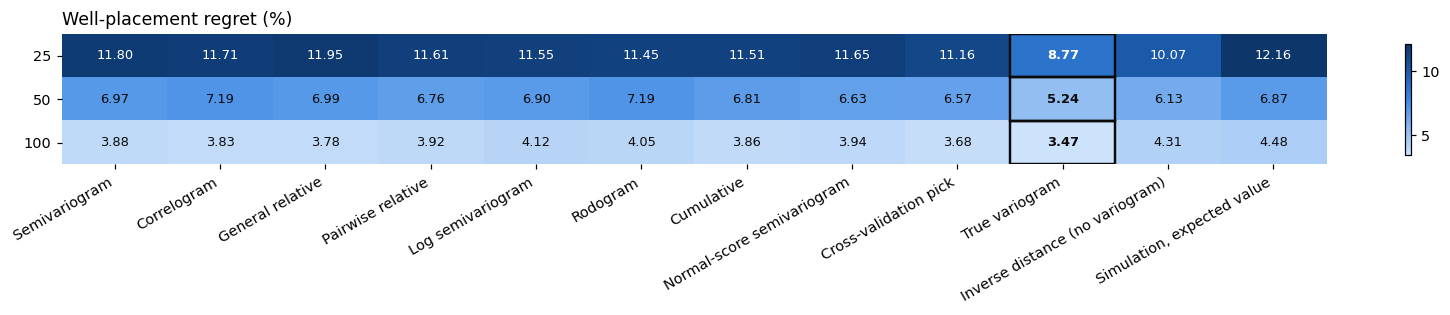

random sites, regret %: {25: 36.6, 50: 36.7, 100: 36.6}


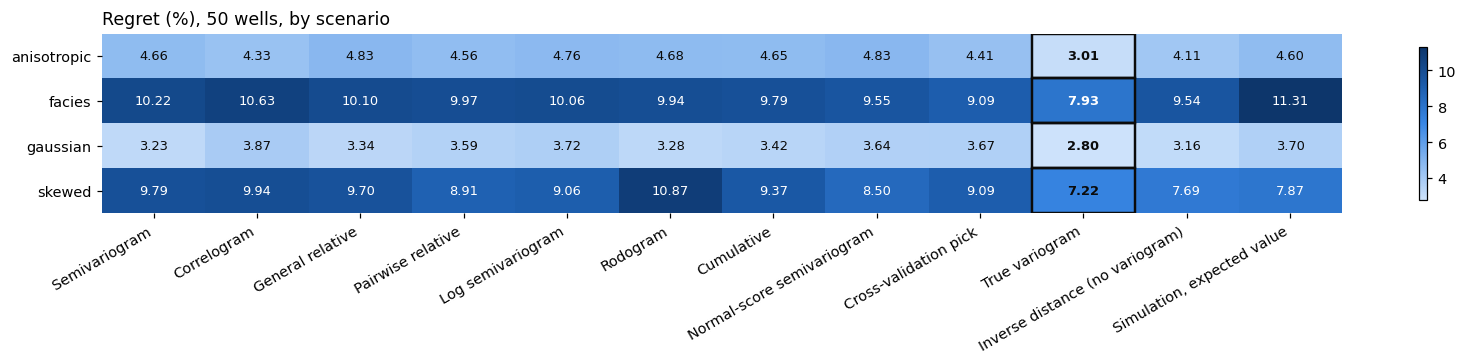

In [6]:
cols = MAPS + ['simulation_ev', 'random']
plots.heat(A.by(dec, 'regret_pct', 'n_wells', 'method', cols[:-1]), 'Well-placement regret (%)', fmt='{:.2f}'); plt.show()
print('random sites, regret %:', dec[dec.method == 'random'].groupby('n_wells').regret_pct.mean().round(1).to_dict())
plots.heat(A.by(dec[dec.n_wells == 50], 'regret_pct', 'scenario', 'method', cols[:-1]), 'Regret (%), 50 wells, by scenario', fmt='{:.2f}'); plt.show()

Each method minus the semivariogram, in $MM per program, averaged within each truth model (30 per scenario,
120 overall) with Holm correction (negative = better than the semivariogram).

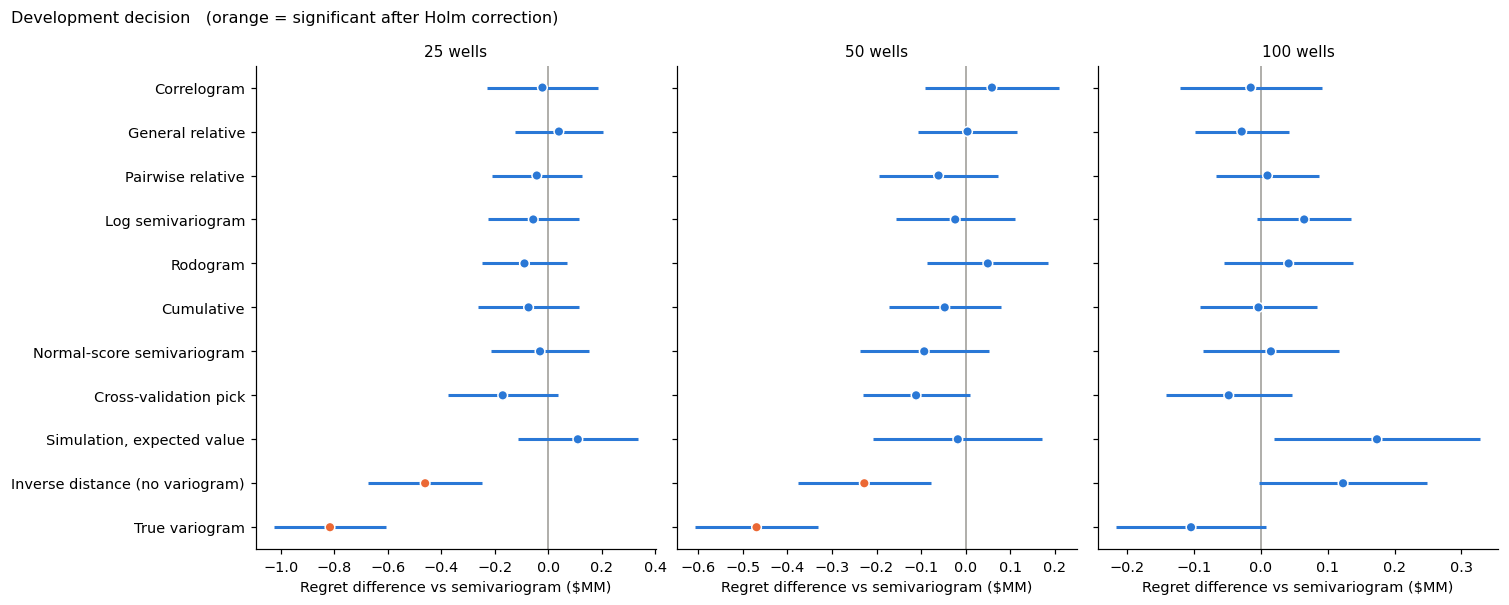

25 wells                                  50 wells                                 100 wells                                
                  mean_diff  ci_lo  ci_hi p_holm pct_better mean_diff  ci_lo  ci_hi p_holm pct_better mean_diff  ci_lo  ci_hi p_holm pct_better
method                                                                                                                                         
correlogram          -0.021 -0.229  0.186  1.000     45.000     0.059 -0.091  0.209  1.000     42.917    -0.015 -0.121  0.091  1.000     37.500
general_relative      0.040 -0.124  0.204  1.000     33.750     0.004 -0.107  0.116  1.000     35.000    -0.029 -0.099  0.041  1.000     33.333
pairwise_relative    -0.042 -0.211  0.126  1.000     37.500    -0.061 -0.194  0.073  1.000     42.083     0.010 -0.067  0.086  1.000     27.917
log                  -0.055 -0.225  0.114  1.000     37.917    -0.023 -0.157  0.110  1.000     39.583     0.065 -0.006  0.135  0.601     25.417
rodogram             -0.088 -0.248  0.071  1.000     44.583     0.050 -0.086  0.185  1.000     41.667     0.042 -0.055  0.138  1.000     35.417
cumulative           -0.073 -0.261  0.115  1.000     47.917    -0.047 -0.172  0.078  1.000     44.167    -0.004 -0.091  0.083  1.000     42.083
normal_score         -0.030 -0.212  0.152  1.000     44.583    -0.093 -0.238  0.052  1.000     40.833     0.015 -0.087  0.117  1.000     25.833
loocv                -0.170 -0.375  0.036  0.939     51.667    -0.111 -0.231  0.009  0.623     41.667    -0.048 -0.143  0.046  1.000     36.250
simulation_ev         0.111 -0.113  0.335  1.000     48.333    -0.018 -0.207  0.172  1.000     45.000     0.174  0.019  0.328  0.304     35.000
idw                  -0.460 -0.673 -0.247  0.000     60.417    -0.227 -0.376 -0.079  0.030     51.667     0.123 -0.003  0.249  0.556     34.583
truth_variogram      -0.816 -1.025 -0.606  0.000     72.083    -0.469 -0.607 -0.331  0.000     67.083    -0.105 -0.217  0.007  0.601     50.000

In [7]:
alts = C.VTYPES[1:] + ['loocv', 'simulation_ev', 'idw', 'truth_variogram']
pt = A.paired_by_wells(dec, 'regret_MM', alts)
plots.forest(pt, 'Regret difference vs semivariogram ($MM)', 'Development decision'); plt.show()
pd.concat({k: v[['mean_diff', 'ci_lo', 'ci_hi', 'p_holm', 'pct_better']] for k, v in pt.items()}, axis=1).round(3)

Scenario by scenario (50 wells): the best alternative to the semivariogram and whether it survives correction.

In [8]:
rows = []
for s in C.SCEN_NAMES:
    t = A.paired_table(dec[(dec.n_wells == 50) & (dec.scenario == s)], 'regret_MM', C.VTYPES[1:] + ['loocv'])
    b = t.mean_diff.idxmin()
    rows.append(dict(scenario=s, best_alternative=C.LABEL[b], diff_MM=t.loc[b, 'mean_diff'], ci_lo=t.loc[b, 'ci_lo'],
                     ci_hi=t.loc[b, 'ci_hi'], p_holm=t.loc[b, 'p_holm']))
pd.DataFrame(rows).set_index('scenario').round(3)

,best_alternative,diff_MM,ci_lo,ci_hi,p_holm
scenario,,,,,
gaussian,Rodogram,0.012,-0.120,0.144,1.000
skewed,Normal-score semivariogram,-0.330,-0.692,0.032,0.579
anisotropic,Correlogram,-0.091,-0.307,0.124,1.000
facies,Cross-validation pick,-0.323,-0.626,-0.020,0.299


## Value of information

What each lever is worth per 3-well program, from the same truth models (positive = less regret).

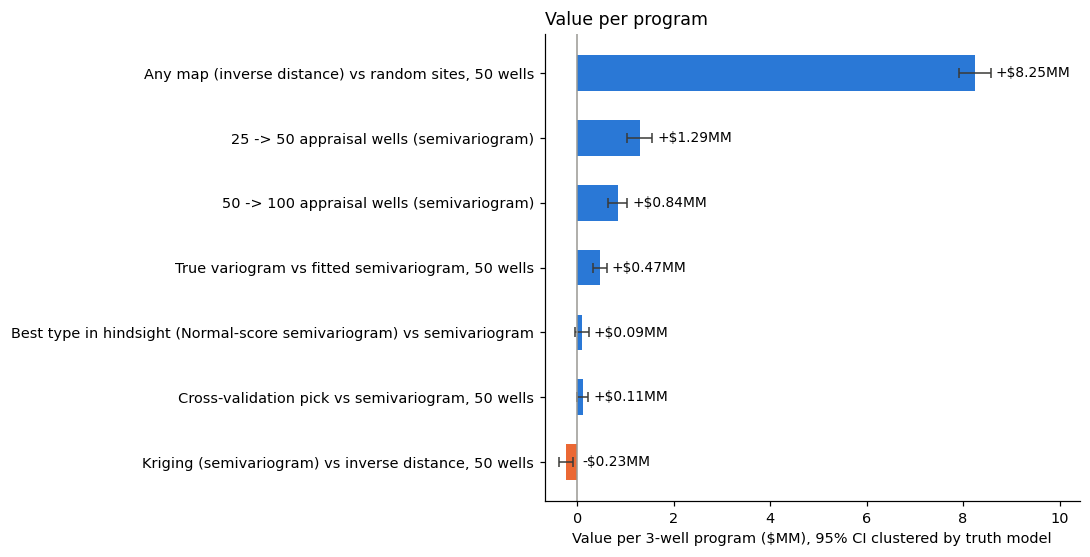

,value_MM,ci_lo,ci_hi,n_truths
lever,,,,
"Any map (inverse distance) vs random sites, 50 wells",8.245,7.916,8.574,120
25 -> 50 appraisal wells (semivariogram),1.295,1.036,1.554,120
50 -> 100 appraisal wells (semivariogram),0.841,0.642,1.041,120
"True variogram vs fitted semivariogram, 50 wells",0.469,0.331,0.607,120
Best type in hindsight (Normal-score semivariogram) vs semivariogram,0.093,-0.052,0.238,120
"Cross-validation pick vs semivariogram, 50 wells",0.111,-0.009,0.231,120
"Kriging (semivariogram) vs inverse distance, 50 wells",-0.227,-0.376,-0.079,120


In [9]:
voi = A.value_of_information(dec)
plots.value_bars(voi, 'Value per program'); plt.show()
voi.round(3)

## Executive summary

Generated from the results above.

In [10]:
def sig(n, alts=C.VTYPES[1:]):
    t = pt[f'{n} wells'].loc[alts]
    better = [C.LABEL[m] for m in t.index if t.loc[m, 'p_holm'] < 0.05 and t.loc[m, 'mean_diff'] < 0]
    worse = [C.LABEL[m] for m in t.index if t.loc[m, 'p_holm'] < 0.05 and t.loc[m, 'mean_diff'] > 0]
    return better, worse
reg = A.by(dec, 'regret_MM', 'n_wells', 'method')
lines = []
for n in C.WELL_COUNTS:
    b, wv = sig(n)
    lines.append(f"- {n} wells: semivariogram regret ${reg.loc[n, 'semivariogram']:.2f}MM; types significantly better: "
                 f"{', '.join(b) or 'none'}; significantly worse: {', '.join(wv) or 'none'}; cross-validation pick "
                 f"{pt[f'{n} wells'].loc['loocv', 'mean_diff']:+.2f}$MM (p_holm {pt[f'{n} wells'].loc['loocv', 'p_holm']:.2f}); "
                 f"inverse distance {pt[f'{n} wells'].loc['idw', 'mean_diff']:+.2f}$MM.")
v = voi.value_MM
cover = 100 * unc.groupby('design').inside_p10_p90.mean()
print('Variogram type and the decision:'); print('\n'.join(lines))
print(f"\nValue per program: more wells 25->50 ${v.iloc[1]:.2f}MM, 50->100 ${v.iloc[2]:.2f}MM; true variogram ${v.iloc[3]:.2f}MM; "
      f"best type in hindsight ${v.iloc[4]:.2f}MM; cross-validation pick ${v.iloc[5]:.2f}MM; kriging over inverse distance ${v.iloc[6]:.2f}MM.")
print(f"Uncertainty: true OOIP inside simulated P10-P90 in {cover['random']:.0f}% of random-well datasets and "
      f"{cover['preferential']:.0f}% of preferential ones (ideal 80%).")

Variogram type and the decision:
- 25 wells: semivariogram regret $3.18MM; types significantly better: none; significantly worse: none; cross-validation pick -0.17$MM (p_holm 0.94); inverse distance -0.46$MM.
- 50 wells: semivariogram regret $1.88MM; types significantly better: none; significantly worse: none; cross-validation pick -0.11$MM (p_holm 0.62); inverse distance -0.23$MM.
- 100 wells: semivariogram regret $1.04MM; types significantly better: none; significantly worse: none; cross-validation pick -0.05$MM (p_holm 1.00); inverse distance +0.12$MM.

Value per program: more wells 25->50 $1.29MM, 50->100 $0.84MM; true variogram $0.47MM; best type in hindsight $0.09MM; cross-validation pick $0.11MM; kriging over inverse distance $-0.23MM.
Uncertainty: true OOIP inside simulated P10-P90 in 62% of random-well datasets and 2% of preferential ones (ideal 80%).
